**Faculty:** Prof. Rajat Subhra Chakraborty, Professor, Department of CSE, IIT Kharagpur

**TA:** Dr. Sabyasachi Mukhopadhyay, Teaching Fellow, Department of CSE, IIT Kharagpur

**Hands-on Objective**

The strongest learning outcome is to let participants calculate token costs, observe hallucination behavior, and practice the SPEC → VERIFY → OVERRIDE workflow in Colab.

**Note:** **SPEC → VERIFY → OVERRIDE** is a disciplined AI-assisted development workflow in which you first **SPEC**ify the task with clear requirements, then **VERIFY** the AI-generated output for correctness, security, and completeness, and finally **OVERRIDE** by modifying, correcting, or rejecting the output whenever it does not meet the desired standards. This approach ensures that humans remain responsible for the final decision, making AI a collaborative assistant rather than an autonomous decision-maker.



**Overview of Basic Theoretical Concepts**

**AI-Native Development:** AI-Native Development is a software development approach in which Artificial Intelligence is integrated as a core component throughout the software lifecycle—from requirements analysis and coding to testing, deployment, and maintenance—rather than being added as an afterthought. It leverages AI to enhance developer productivity, automate repetitive tasks, and enable the creation of intelligent, adaptive, and user-centric applications.

**Vibe Coding:** Vibe Coding is an AI-assisted programming approach in which developers describe their intent in natural language and iteratively collaborate with AI to generate, refine, and validate code while maintaining human oversight.

**Example:** A developer writes, *"Create a Python program that predicts house prices using Random Forest and explains the predictions using SHAP,"* and the AI generates the initial code. The developer then reviews, tests, and refines the AI-generated code by following the **SPEC → VERIFY → OVERRIDE** workflow until the solution meets the desired requirements.



**Packages essential for this hands-on session**

| **Package**       | **Task**                                                                                                              |
| ----------------- | --------------------------------------------------------------------------------------------------------------------- |
| **transformers**  | Provides pre-trained AI models for tasks such as text generation, translation, summarization, and question answering. |
| **tiktoken**      | Tokenizes text and counts tokens to estimate LLM input/output costs.                                                  |
| **sentencepiece** | Performs subword tokenization for training and using modern language models.                                          |
| **pandas**        | Manipulates, analyzes, and processes structured data using DataFrames.                                                |
| **matplotlib**    | Creates graphs, charts, and visualizations for data analysis and presentation.                                        |


**cl100k_base** : It is the tokenization scheme used by many OpenAI language models to convert text into tokens for efficient processing and accurate token counting.

**Why do we need cl100k_base?**

(i) Splits text into tokens before sending it to an LLM.

(ii) Counts the number of input and output tokens, which is important for estimating API usage and cost.

(iii) Uses the same tokenization method as many OpenAI models (e.g., GPT-4 and GPT-3.5 Turbo), ensuring accurate token counts.

(iv) Optimizes text encoding by efficiently handling words, punctuation, numbers, and special characters.

It acts like a translator between human language and the numerical token format that an LLM understands.

**For example:**

**Input Text:**

Artificial Intelligence is amazing.

After applying the cl100k_base tokenizer, it may be converted into tokens like:

[9473, 16895, 374, 8056, 13]

These numbers (token IDs) are what the model actually processes—not the original text.

**Note:** Since this is for a Google Colab hands-on session, I'll use only free / open-source libraries and Hugging Face Inference API where possible so that participants can execute everything without requiring a paid OpenAI API key.

**Install Required Libraries**

In [1]:
!pip -q install transformers tiktoken sentencepiece pandas matplotlib
#installs the required Python libraries (Transformers, Tiktoken,
#SentencePiece, Pandas, and Matplotlib) in Google Colab using the pip package
#manager, while the -q option minimizes installation messages for a cleaner output.

**Import Libraries**

In [2]:
import pandas as pd
#Imports the Pandas library and assigns it the alias pd
import matplotlib.pyplot as plt
#Imports the pyplot module from the Matplotlib library with the alias plt
import tiktoken
#Imports the Tiktoken library

**Activity 1: Token Counting**

In [4]:
# Example paragraph

text = """                                                            #Creates a text variable to store data. Defines a multi-line string.
Artificial Intelligence (AI) is transforming software engineering by
enabling AI-native development, automated code generation,
and intelligent software testing.
"""

print(text)
#Displays the contents of the text variable on the screen.

                                                            #Creates a text variable to store data. Defines a multi-line string.
Artificial Intelligence (AI) is transforming software engineering by
enabling AI-native development, automated code generation,
and intelligent software testing.



In [5]:
encoding = tiktoken.get_encoding("cl100k_base")
#Creates a variable named encoding to store the tokenizer object
#that will be used to convert text into tokens.

In [6]:
tokens = encoding.encode(text)
#Creates a variable named tokens to store the tokenized version of the input text.

print(tokens)
#The print() function displays the list of token IDs generated by the tokenizer.
print("Number of tokens:", len(tokens))
#This statement prints the total number of tokens generated from the input text.

[12216, 674, 55968, 264, 1495, 3977, 311, 3637, 828, 13, 38926, 264, 7447, 8614, 925, 627, 9470, 16895, 22107, 320, 15836, 8, 374, 46890, 3241, 15009, 555, 198, 268, 19295, 15592, 15971, 4500, 11, 28598, 2082, 9659, 345, 438, 25530, 3241, 7649, 627]
Number of tokens: 43


**Output Explanation:** Each number represents a unique token recognized by the tokenizer.

Then, the len() function calculates the total number of elements (tokens) in the tokens list.

**Activity 2: Token Visualization**

In [9]:
decoded = [encoding.decode([i]) for i in tokens]
#Stores all decoded tokens in a list.

df = pd.DataFrame({
#Creates a table (DataFrame) with rows and columns.
    "Token ID":tokens,
#Creates the first column containing token IDs.
    "Decoded Token":decoded
#Creates the second column containing decoded text.
})

df
#Displays the DataFrame in Google Colab or Jupyter Notebook

,Token ID,Decoded Token
0,12216,...
1,674,#
2,55968,Creates
3,264,a
4,1495,text
5,3977,variable
6,311,to
7,3637,store
8,828,data
9,13,.


**Output Explanation:** The output displays a **Pandas DataFrame** with two columns: **Token ID**, which contains the numerical IDs assigned by the tokenizer, and **Decoded Token**, which shows the corresponding human-readable text for each token. This table illustrates how the **`cl100k_base` tokenizer** splits the original input text into smaller units (tokens) that a Large Language Model (LLM) processes internally.


**Activity 3: Estimate OpenAI API Cost**

In [10]:
input_tokens = len(tokens)
#Counts the total number of input tokens.

output_tokens = 300
#Assumes the AI will generate 300 output tokens.

gpt41_input_price = 2.00
#Stores the input token price (USD per million tokens).

gpt41_output_price = 8.00
#Stores the output token price (USD per million tokens).

cost = ((input_tokens/1_000_000)*gpt41_input_price)+((output_tokens/1_000_000)*gpt41_output_price)
#Calculates the total API cost based on input and output token usage.

print(f"Estimated Cost (USD): ${cost:.8f}")
#Displays the estimated API cost in a formatted manner.

Estimated Cost (USD): $0.00248600


**Output Explanation:** This output indicates that processing the given prompt and generating the expected response would cost approximately **USD 0.002486** (about **0.25 cents**) using the specified pricing model. The estimate is calculated by combining the costs of the **input tokens** and the **expected output tokens**, demonstrating how API pricing depends on the number of tokens processed by the Large Language Model.


**Activity 4: Convert Cost into INR**

In [11]:
usd_to_inr = 95
#Creates a variable named usd_to_inr to store the exchange rate between the US Dollar (USD) and the Indian Rupee (INR).

cost_inr = cost*usd_to_inr
#This statement converts the estimated API cost from US dollars to Indian Rupees using the specified exchange rate.

print(f"Estimated Cost (INR): ₹{cost_inr:.5f}")
#This statement prints the estimated API cost in Indian Rupees with five decimal places.

Estimated Cost (INR): ₹0.23617


**Output Explanation:** The output Estimated Cost (INR): ₹0.23617 indicates that processing the given prompt and generating the expected AI response would cost approximately 24 paise (₹0.23617) based on the assumed exchange rate of 1 USD = ₹95.

**Activity 5: Compare Prompt Costs**

In [12]:
prompt1 = """
Explain Deep Learning.             #Creates a variable named prompt1 to store the first prompt.
"""

prompt2 = """                      #Creates another variable named prompt2.
Explain Deep Learning in detail with mathematical derivations,
historical development,
real-world applications,
advantages,
limitations,
future scope,
code examples,
research papers,
and references.
"""

tokens1 = len(encoding.encode(prompt1))
#This statement calculates the number of tokens required to represent the short prompt.
tokens2 = len(encoding.encode(prompt2))
#This statement calculates the number of tokens required for the detailed prompt.

print(tokens1,tokens2)
#This statement prints the number of tokens in both prompts so that they can be compared.

20 45


**Output Explanation:** Since Prompt 2 contains more words and instructions, it requires more tokens than Prompt 1.

The exact token counts may vary depending on the tokenizer version, model, or encoding scheme used (e.g., cl100k_base, o200k_base, etc.). Different tokenizers apply different rules for splitting words, punctuation, spaces, and special characters into tokens. Consequently, the same input text may produce slightly different token counts across different LLMs or tokenizer implementations, leading to minor variations in API cost estimation.

**Visualization**

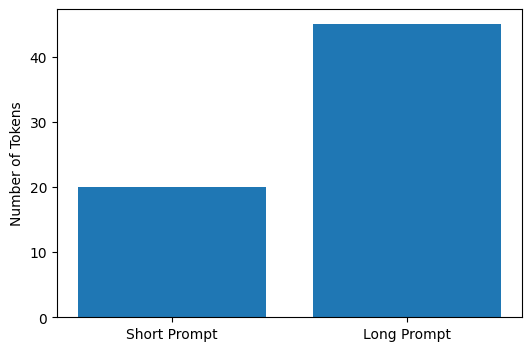

In [13]:
plt.figure(figsize=(6,4))
#This statement creates a new plotting area with a width of 6 inches and a height of 4 inches.

plt.bar(["Short Prompt","Long Prompt"],[tokens1,tokens2])
#Specifies the labels to be displayed on the X-axis

plt.ylabel("Number of Tokens")
#Specifies the text that will appear along the Y-axis.

plt.show()
#Displays the completed graph on the screen.

**Output Explanation:** The output is a **bar chart** comparing the number of tokens in the **Short Prompt** and the **Long Prompt**. It clearly shows that the **Long Prompt contains significantly more tokens than the Short Prompt**, demonstrating that more detailed prompts require more computational resources and generally result in higher API usage and cost when processed by a Large Language Model (LLM).


**Activity 7: Token Savings Percentage**

In [14]:
prompt_old = "Write a detailed explanation of Artificial Intelligence with adequate examples."
#This statement stores the original prompt that will later be tokenized
#and compared.

prompt_new = "Explain AI in 5 sentences."
#This statement stores the compressed prompt, which is expected to use fewer tokens.

old_tokens = len(encoding.encode(prompt_old))
#This statement calculates the number of tokens required for the original prompt.
new_tokens = len(encoding.encode(prompt_new))
#This statement calculates the number of tokens required for the compressed prompt.

print("Original:",old_tokens)
#This statement displays the number of tokens in the original prompt.

print("Compressed:",new_tokens)
#Displays the token count of the compressed prompt along with the label "Compressed:".

print("Saved:",old_tokens-new_tokens)
#This statement calculates and prints the number of tokens saved by rewriting the prompt more concisely.

Original: 11
Compressed: 8
Saved: 3


**Output Explanation:** This output indicates that the original prompt contains 11 tokens, while the compressed prompt contains 8 tokens, resulting in a reduction of 3 tokens. It demonstrates that rewriting a prompt more concisely can reduce the number of input tokens, leading to lower API usage and potentially lower inference costs when using a Large Language Model.

**Note:** A shorter sentence does not necessarily mean fewer tokens; tokenization depends on how the tokenizer splits the text into subword units.

In [15]:
saving = (old_tokens-new_tokens)/old_tokens*100
#This statement calculates the percentage reduction in the number of tokens after rewriting
#the prompt.

print(f"Token Saving = {saving:.2f}%")
#Displays the percentage of token savings with two decimal places.

Token Saving = 27.27%


**Output Explanation:** The output `Token Saving = 27.27%` means that the compressed prompt uses 27.27% fewer tokens than the original prompt. In this example, the token count was reduced from 11 tokens to 8 tokens, saving 3 tokens, and the percentage saving is calculated as (3 ÷ 11) × 100 = 27.27%, indicating a reduction in API usage and potentially lower processing cost.


**Activity 8: Hallucination Demonstration**

Instead of using GPT, students inspect prompts.


In [16]:
unsafe_prompt = """                                          #Creates a variable named unsafe_prompt.
                                                             #Triple quotation marks (""" """) create a multi-line string in Python.
Write three research papers by John Doe published in 2026.   #This prompt is called unsafe because it asks the AI to generate research papers without providing any supporting or trusted information.
                                                             #If no such papers exist, the AI may hallucinate (invent) paper titles.
"""

safe_prompt = """
#Creates another variable named safe_prompt.

Using ONLY the bibliography given below,
#The prompt explicitly instructs the AI to use only the supplied bibliography.
#The word ONLY restricts the AI from using outside knowledge.

list papers published in 2026.
#Specifies the exact task the AI must perform.

Bibliography:
#Introduces the trusted source of information.

1....
#Represents the list of research papers (placeholder bibliography).
#The AI should search only within these entries.

2....
3....
"""

print("Unsafe Prompt:\n")
#Prints the heading Unsafe Prompt. \n is the newline character, which moves the cursor to the next line.

print(unsafe_prompt)
#Displays the contents stored in the variable unsafe_prompt.

print()
#Prints an empty line. Used only to improve the readability of the output.

print("Safe Prompt:\n")
#Displays space followed by a blank line.

print(safe_prompt)
#Displays the complete safe prompt.


Unsafe Prompt:

                                          #Creates a variable named unsafe_prompt.
                                                             #Triple quotation marks () create a multi-line string in Python.
Write three research papers by John Doe published in 2026.   #This prompt is called unsafe because it asks the AI to generate research papers without providing any supporting or trusted information.
                                                             #If no such papers exist, the AI may hallucinate (invent) paper titles.


Safe Prompt:

    
#Creates another variable named safe_prompt.

Using ONLY the bibliography given below,      
#The prompt explicitly instructs the AI to use only the supplied bibliography.
#The word ONLY restricts the AI from using outside knowledge.

list papers published in 2026.  
#Specifies the exact task the AI must perform.

Bibliography:        
#Introduces the trusted source of information.

1....                               

**Activity 9: Grounded Generation Concept**

In [17]:
bibliography = [
#Creates a variable named bibliography to store multiple research paper titles.
    "Paper A (2024)",
#String elements stored inside a Python list.
    "Paper B (2025)",
#String elements stored inside a Python list.
    "Paper C (2026)"
#String elements stored inside a Python list.
]

year = "2026"
#Creates a variable named year and stores the value "2026" as a string.

for paper in bibliography:
#This is a for loop that iterates through each element of the bibliography list
    if year in paper:
#This is an if statement that checks whether the value stored in the variable year (i.e., "2026") is present
#anywhere within the current paper title.
        print(paper)
#If the condition in the if statement is True, the corresponding paper title is displayed on the screen.


Paper C (2026)


**Output Explanation:** Since only "Paper C (2026)" contains "2026", only this paper is printed.

AI should only answer with trusted data. It emphasizes the principle of grounded AI, where an AI model generates responses based solely on reliable, verified, and authorized information instead of relying on its internal knowledge or making assumptions.

**Significance:**

**(i) Reduces hallucinations:** Prevents the AI from generating fabricated or inaccurate information.

**(ii) Improves reliability:** Ensures that responses are based on authentic and trustworthy sources.

**(iii) Enhances transparency:** Users can trace answers back to the underlying data or documents.

**(iv) Essential for high-stakes applications:** In domains such as healthcare, finance, law, and education, decisions must rely on validated information.

**(v) Supports Retrieval-Augmented Generation (RAG):** The AI first retrieves relevant information from trusted documents or databases before generating a response.

**(vi) Builds user trust:** Users are more likely to trust AI systems whose responses are grounded in credible sources.

## **Conclusions**

By the end of this hands-on session, participants should be able to:

* Understand the fundamentals of **AI-native software development** and its role in modern software engineering.
* Explain how **LLMs tokenize text** and estimate the computational cost of AI applications using token-based pricing.
* Design **effective and concise prompts** to improve model performance while minimizing API costs.
* Recognize the causes of **AI hallucinations** and apply grounding techniques to generate more reliable outputs.
* Apply the **SPEC → VERIFY → OVERRIDE** workflow to responsibly use AI-generated code and content.
* Distinguish between **rule-based systems, AI-based systems, and hybrid approaches** for real-world applications.
* Appreciate the importance of **human oversight, validation, and ethical AI practices** in AI-assisted software development.
* Gain practical experience in implementing AI concepts using **Google Colab**, preparing them for more advanced AI application development.

---

### **Key Takeaway**

> AI is a powerful collaborator—not a replacement for human expertise. Successful AI-native development combines clear specifications, critical verification, and responsible human decision-making to build reliable, trustworthy, and efficient intelligent systems.
